# Data Exploration

This notebook explores the `ogbl-ddi` dataset. Each node is a drug. Each edge is a known interaction between two drugs.

In [1]:
!git clone https://github.com/AidaKhaleghi/Drug-Drug-Interaction_GNN.git

Cloning into 'Drug-Drug-Interaction_GNN'...
remote: Enumerating objects: 37, done.
remote: Counting objects: 100% (37/37), done.
remote: Compressing objects: 100% (25/25), done.
remote: Total 37 (delta 9), reused 34 (delta 6), pack-reused 0 (from 0)
Receiving objects: 100% (37/37), 14.37 KiB | 639.00 KiB/s, done.
Resolving deltas: 100% (9/9), done.


In [2]:
%cd Drug-Drug-Interaction_GNN
!pip install -e .
%cd src

/content/Drug-Drug-Interaction_GNN
Obtaining file:///content/Drug-Drug-Interaction_GNN
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 78.8/78.8 kB 3.1 MB/s eta 0:00:00
  Building editable for ddi-gnn (pyproject.toml) ... done
  Created wheel for ddi-gnn: filename=ddi_gnn-0.1.0-0.editable-py3-none-any.whl size=1361 sha256=74352af9e83cf29bc7d95bbfcfd40243602b74380bc3792a9e7ab6a039d012bd
  Stored in directory: /tmp/pip-ephem-wheel-cache-z7ieaqku/wheels/63/fe/5a/b9cbc227ff9c228bfc5d2769fc7692465b22192c47fd5bf8b1
Successfully built ddi-gnn
/content/Drug-Drug-Interaction_GNN/src


In [3]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import torch

from ddi_gnn.data import load_ddi
from ddi_gnn.plotting import plot_graph

DATA_ROOT = "/content/datasets"

data = load_ddi(root=DATA_ROOT)

Downloaded 0.04 GB: 100%|██████████| 46/46 [00:04<00:00,  9.22it/s]


Extracting /content/datasets/ddi.zip
Loading necessary files...
This might take a while.
Processing graphs...


100%|██████████| 1/1 [00:00<00:00, 37.66it/s]

Saving...


## Size and density

In [4]:
all_edges = torch.cat([pairs.pos for pairs in data.splits.values()])
n_edges = all_edges.shape[0]
print(f"The graph contains {data.n_nodes} drugs and {n_edges} interactions.")

n_possible = data.n_nodes * (data.n_nodes - 1) // 2
print(f"There are {n_possible} possible pairs, so the graph density is {n_edges / n_possible:.1%}.")

The graph contains 4267 drugs and 1334889 interactions.
There are 9101511 possible pairs, so the graph density is 14.7%.


## Degree distribution

The degree of a drug is the number of other drugs it interacts with.

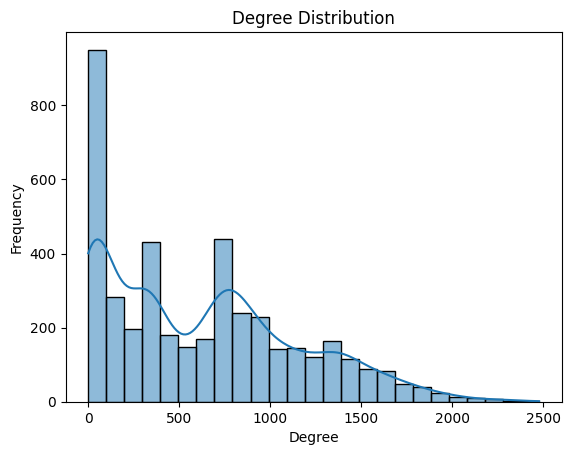

In [5]:
degrees = np.bincount(all_edges.flatten().numpy(), minlength=data.n_nodes)

sns.histplot(degrees, kde=True)
plt.xlabel("Degree")
plt.ylabel("Frequency")
plt.title("Degree Distribution")
plt.show()

## Splits

In [6]:
for name, pairs in data.splits.items():
    print(f"{name:>5}: {len(pairs.pos):>9} positive pairs, {len(pairs.neg):>9} negative pairs")

train:   1067911 positive pairs,   8033600 negative pairs
valid:    133489 positive pairs,    101882 negative pairs
 test:    133489 positive pairs,     95599 negative pairs


In [7]:
# Does every validation and test drug also appear in the training edges?
train_nodes = set(data.splits["train"].pos.flatten().tolist())
for name in ("valid", "test"):
    nodes = set(data.splits[name].pos.flatten().tolist())
    print(f"All {name} drugs are in the training edges: {nodes <= train_nodes}")

All valid drugs are in the training edges: True
All test drugs are in the training edges: True


## Drug names

In [8]:
print(f"Drugs without a name: {data.annotation['drug_name'].isna().sum()}")

top_drugs = data.annotation.assign(degree=degrees[data.annotation["node_id"]])
top_drugs.nlargest(10, "degree")[["node_id", "drug_name", "degree"]]

Drugs without a name: 0


,node_id,drug_name,degree
807,807,Quinidine,2477
406,406,Chlorpromazine,2431
1037,1037,Desipramine,2345
260,260,Amitriptyline,2338
299,299,Clozapine,2324
1029,1029,Doxepin,2273
431,431,Haloperidol,2269
1123,1123,Clomipramine,2269
485,485,Carbamazepine,2267
390,390,Imipramine,2260


## Visualizing a subgraph

K randomly chosen drugs and the training interactions between them.

The subgraph has 2721 interactions.


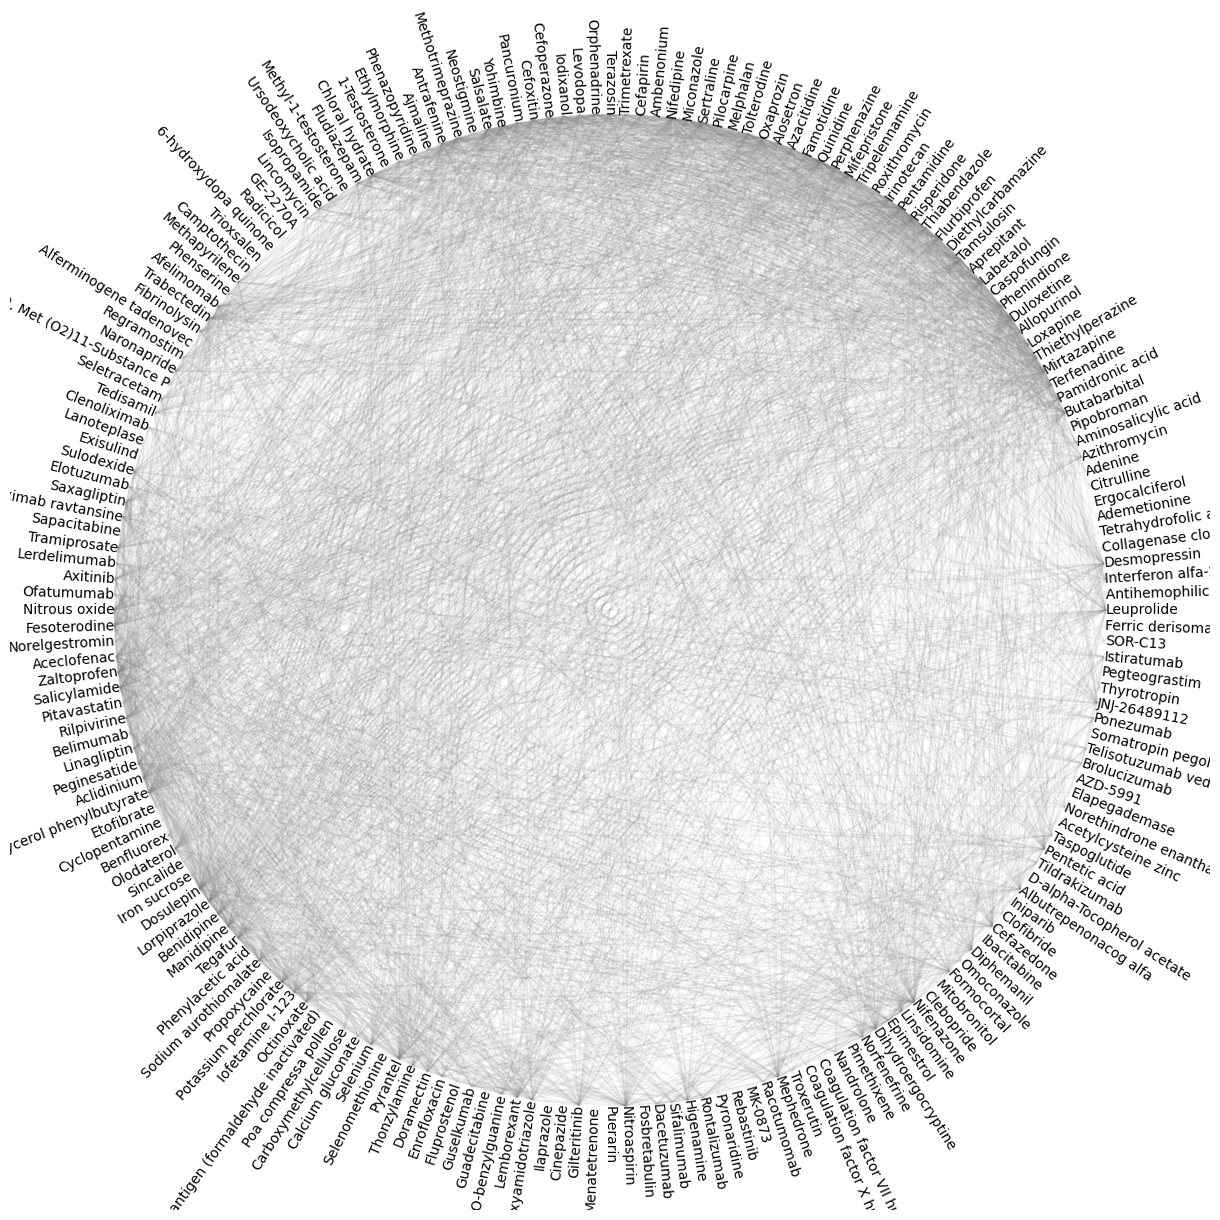

In [10]:
generator = torch.Generator().manual_seed(42)
K = 200
small = load_ddi(root=DATA_ROOT, node_limit=K, generator=generator)
print(f"The subgraph has {small.graph.edge_index.shape[1] // 2} interactions.")

plot_graph(small, figsize=(12, 12))
plt.show()